In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

In [2]:
con = duckdb.connect()

con.read_parquet("../Data/Processed/reviews_clean.parquet").create_view("reviews");

## Review Score Distribution

Calculating the number of reviews for each score:

In [3]:
score_distribution = con.sql("""
    SELECT
        review_score,
        COUNT(*) AS review_count
    FROM reviews
    GROUP BY review_score
    ORDER BY review_score
""").df()

display(score_distribution)

,review_score,review_count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


Calculating the percentage for each score:

In [4]:
score_distribution['percentage'] = (score_distribution['review_count'] / score_distribution['review_count'].sum()) * 100
display(score_distribution)

,review_score,review_count,percentage
0,1,11424,11.513344
1,2,3151,3.175643
2,3,8179,8.242965
3,4,19142,19.291704
4,5,57328,57.776344


The most repeated review score is **5/5** (with a frequency of **57%**), and the least repeated review score is **2/5** (with a frequency of **3%**)

We'll visualize this to have a better understanding:

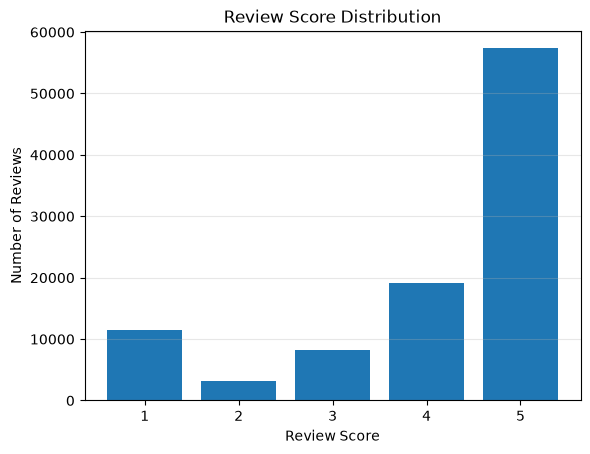

In [5]:
plt.bar(score_distribution['review_score'], score_distribution['review_count'])

plt.title('Review Score Distribution')
plt.xlabel('Review Score')
plt.ylabel('Number of Reviews')

plt.grid(axis='y', alpha=0.3)
plt.show()

## Overall Customer Satisfaction

Calculating the overall review score (average):

In [6]:
overall_score = (score_distribution['review_score'] * score_distribution['review_count']).sum() / score_distribution['review_count'].sum()
print(f"Overall review score: {overall_score.round(2)}")

Overall review score: 4.09


Finding out what percentage of scores are `positive` (4 and 5) or `negative` (1 and 2) or `neutral` (3):

In [7]:
score_groups = score_distribution.copy()

score_groups['review_score'] = score_groups['review_score'].replace({
    1: 'Negative',
    2: 'Negative',
    3: 'Neutral',
    4: 'Positive',
    5: 'Positive'
})

score_groups = score_groups.groupby('review_score', as_index=False).sum()

display(score_groups)

,review_score,review_count,percentage
0,Negative,14575,14.688987
1,Neutral,8179,8.242965
2,Positive,76470,77.068048


Putting all the satisfaction metrics together:

In [8]:
total_reviews = score_distribution['review_count'].sum()
positive_rate = score_groups.loc[score_groups['review_score'] == 'Positive', 'percentage'].values[0]
negative_rate = score_groups.loc[score_groups['review_score'] == 'Negative', 'percentage'].values[0]

print(f"Total number of reviews: {total_reviews:,}")
print(f"Overall average score: {overall_score:.2f}")
print(f"Positive review rate (4 and 5): {positive_rate:.2f}%")
print(f"Negative review rate (1 and 2): {negative_rate:.2f}%")

Total number of reviews: 99,224
Overall average score: 4.09
Positive review rate (4 and 5): 77.07%
Negative review rate (1 and 2): 14.69%


Not every order has a review, so let's check how many orders are covered:

In [9]:
con.read_parquet("../Data/Processed/orders_clean.parquet").create_view("orders");

coverage = con.sql("""
    SELECT
        (SELECT COUNT(*) FROM orders) AS total_orders,
        COUNT(DISTINCT order_id) AS reviewed_orders
    FROM reviews
""").df()

coverage['reviewed_percent'] = coverage['reviewed_orders'] / coverage['total_orders'] * 100
display(coverage)

,total_orders,reviewed_orders,reviewed_percent
0,99441,98673,99.227683


#### Overall Satisfaction: Conclusion
- The average of **4.09** looks good, and more than 3 out of 4 reviews are positive.
- But the average hides a problem: **1 star is the third most common score (11.51%)**, much more common than 2 stars (3.18%) or 3 stars (8.24%). Customers are mostly either very happy or very unhappy, and about **1 in 7 reviews is negative**.
- So it is better to follow the **negative rate** next to the average. A small change in the average can hide a big change in the number of unhappy customers.

**Coverage:** 98,673 of the 99,441 orders (99.23%) have at least one review, so the reviews cover almost all orders. Still, customers who choose to write a review may not be fully representative of all customers.

## Satisfaction by Product Category

We want to obtain three columns:
- order_id
- review_score
- product_category_name

In [10]:
con.read_parquet("../Data/Processed/products_clean.parquet").create_view("products");
con.read_parquet("../Data/Processed/order_items_clean.parquet").create_view("order_items");

A review belongs to an **order**, but an order can have several items. If we join reviews with order items, an order with 3 items gets its review counted 3 times. Let's check:

In [11]:
plain_join = con.sql("""
    SELECT COUNT(*) AS row_count
    FROM reviews r
    JOIN order_items oi
        ON r.order_id = oi.order_id
""").df()

print(f"reviews in the reviews table: {total_reviews:,}")
print(f"rows after a plain join with order_items: {plain_join['row_count'][0]:,}")

reviews in the reviews table: 99,224
rows after a plain join with order_items: 112,372


To avoid this, we keep **one row per review and category** (`SELECT DISTINCT`). If an order has products from two different categories, its review is counted once in each of them.

Note: the review score is for the **whole order**, not for one product. So "category score" below means "average score of orders that contain this category".

In [12]:
reviews_products = con.sql("""
    SELECT DISTINCT
        r.review_id,
        r.order_id,
        r.review_score,
        p.product_category_name
    FROM reviews r
    JOIN order_items oi
        ON r.order_id = oi.order_id
    JOIN products p
        ON oi.product_id = p.product_id
""").df()

display(f"rows after removing duplicates: {len(reviews_products):,}")
display(reviews_products.head())

'rows after removing duplicates: 99,273'

,review_id,order_id,review_score,product_category_name
0,97ca439bc427b48bc1cd7177abe71365,00010242fe8c5a6d1ba2dd792cb16214,5,cool_stuff
1,7e92c32ae297ef950ee69781d9f1760c,00061f2a7bc09da83e415a52dc8a4af1,5,health_beauty
2,b5c9aa83935388c89bd9b1b2ce6d1439,0013503b13da1eac686219390b7d641b,5,furniture_decor
3,f7bbac6b6901d7636435ea406a856e34,0017afd5076e074a48f1f1a4c7bac9c5,1,computers_accessories
4,0d4256cffb82f343514d85b4f2181d39,004eab0fd8f28adaf8d488976f77febe,5,sports_leisure


In [13]:
category_scores = reviews_products.groupby('product_category_name').agg(
    average_score=('review_score', 'mean'),
    review_count=('review_score', 'count')
).reset_index()

display(category_scores.head())

,product_category_name,average_score,review_count
0,agro_industry_and_commerce,4.021978,182
1,air_conditioning,4.028112,249
2,art,4.025000,200
3,arts_and_craftmanship,4.173913,23
4,audio,3.827586,348


Highest scores:

In [14]:
top_10 = category_scores.sort_values('average_score', ascending=False).head(10)

display(top_10)

,product_category_name,average_score,review_count
11,cds_dvds_musicals,4.666667,12
29,fashion_childrens_clothes,4.500000,8
8,books_general_interest,4.462598,508
22,costruction_tools_tools,4.425532,94
10,books_technical,4.405405,259
35,flowers,4.392857,28
37,food_drink,4.385965,228
53,luggage_accessories,4.331068,1030
9,books_imported,4.320755,53
66,small_appliances_home_oven_and_coffee,4.293333,75


Lowest scores:

In [15]:
bottom_10 = category_scores.sort_values('average_score', ascending=True).head(10)

display(bottom_10)

,product_category_name,average_score,review_count
63,security_and_services,2.500000,2
59,pc_gamer,3.125000,8
62,portable_kitchen_and_food_preparers,3.428571,14
57,office_furniture,3.617508,1268
30,fashion_male_clothing,3.702703,111
27,fashio_female_clothing,3.731707,41
23,diapers_and_hygiene,3.740741,27
41,furniture_mattress_and_upholstery,3.815789,38
46,home_comfort_2,3.826087,23
4,audio,3.827586,348


Many of these categories have very few reviews (e.g. `security_and_services` has only 2), so their average is not reliable. Let's look at the categories with fewer than 30 reviews:

In [16]:
small_categories = category_scores[category_scores['review_count'] < 30].sort_values('average_score')

print(f"categories with fewer than 30 reviews: {len(small_categories)} of {len(category_scores)}")
display(small_categories)

categories with fewer than 30 reviews: 11 of 74


,product_category_name,average_score,review_count
63,security_and_services,2.500000,2
59,pc_gamer,3.125000,8
62,portable_kitchen_and_food_preparers,3.428571,14
23,diapers_and_hygiene,3.740741,27
46,home_comfort_2,3.826087,23
3,arts_and_craftmanship,4.173913,23
52,la_cuisine,4.250000,12
32,fashion_sport,4.285714,28
35,flowers,4.392857,28
29,fashion_childrens_clothes,4.500000,8


To get a fair ranking, we only keep categories with **at least 100 reviews**:

In [17]:
reliable = category_scores[category_scores['review_count'] >= 100]
print(f"categories with at least 100 reviews: {len(reliable)}")

top_10_reliable = reliable.sort_values('average_score', ascending=False).head(10)
bottom_10_reliable = reliable.sort_values('average_score', ascending=True).head(10)

print("Highest scores (at least 100 reviews):")
display(top_10_reliable)
print("Lowest scores (at least 100 reviews):")
display(bottom_10_reliable)

categories with at least 100 reviews: 52
Highest scores (at least 100 reviews):


,product_category_name,average_score,review_count
8,books_general_interest,4.462598,508
10,books_technical,4.405405,259
37,food_drink,4.385965,228
53,luggage_accessories,4.331068,1030
36,food,4.276404,445
68,stationery,4.244136,2302
61,pet_shop,4.238990,1703
31,fashion_shoes,4.213389,239
21,costruction_tools_garden,4.198980,196
60,perfumery,4.198420,3165


Lowest scores (at least 100 reviews):


,product_category_name,average_score,review_count
57,office_furniture,3.617508,1268
30,fashion_male_clothing,3.702703,111
4,audio,3.827586,348
19,construction_tools_safety,3.849398,166
47,home_confort,3.859296,398
34,fixed_telephony,3.902326,215
72,unknown,3.913674,1448
33,fashion_underwear_beach,3.933333,120
7,bed_bath_table,3.968617,9432
48,home_construction,3.969262,488


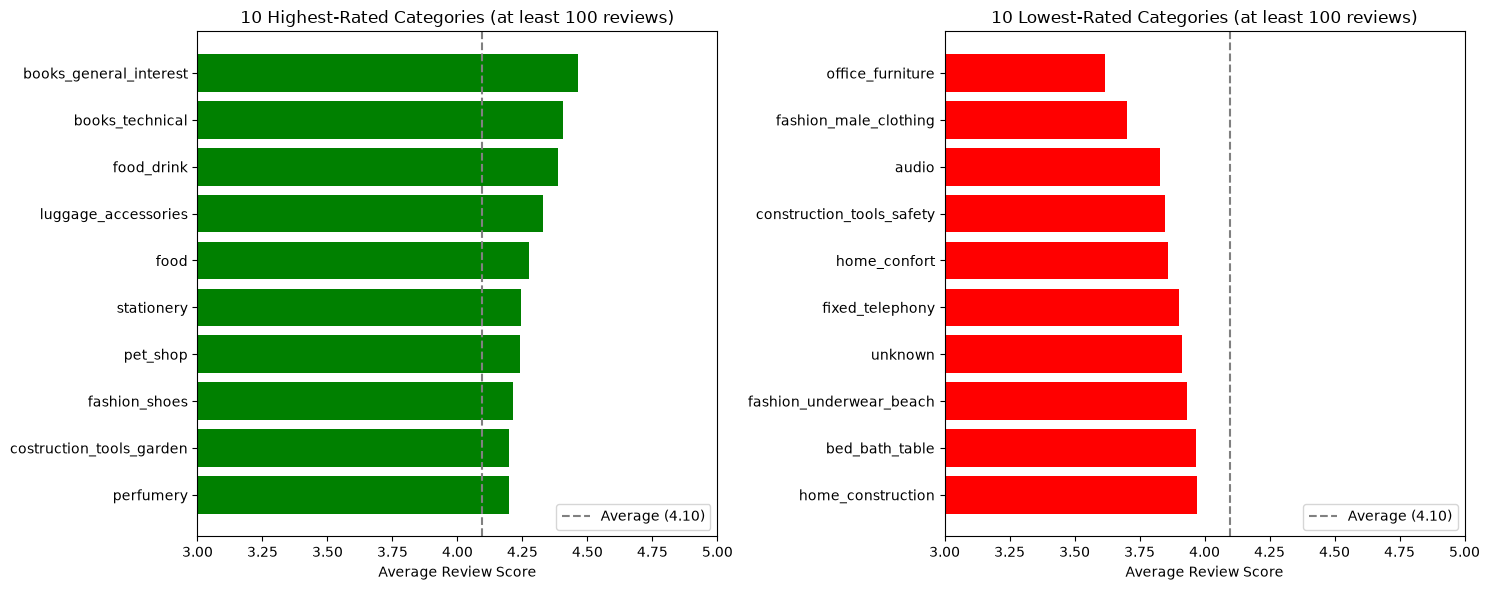

In [18]:
category_average = reviews_products['review_score'].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# sort ascending so the best one is on top of the chart
top_chart = top_10_reliable.sort_values('average_score')
ax1.barh(top_chart['product_category_name'], top_chart['average_score'], color='green')
ax1.set_title('10 Highest-Rated Categories (at least 100 reviews)')

bottom_chart = bottom_10_reliable.sort_values('average_score', ascending=False)
ax2.barh(bottom_chart['product_category_name'], bottom_chart['average_score'], color='red')
ax2.set_title('10 Lowest-Rated Categories (at least 100 reviews)')

for ax in (ax1, ax2):
    ax.axvline(category_average, color='gray', linestyle='--', label=f'Average ({category_average:.2f})')
    ax.set_xlim(3, 5)
    ax.set_xlabel('Average Review Score')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

#### Satisfaction by Product Category: Conclusion

**How the data was prepared:** a plain join between reviews and order items gives 112,372 rows for 99,224 reviews, because orders with several items repeat the same review. After keeping one row per review and category, there are 99,273 rows. The score is still an **order-level** score: it tells us how customers rated orders that contain a category, not the product itself.

**Small categories are misleading:** 11 of the 74 categories have fewer than 30 reviews. The raw top and bottom lists are full of them:
- `cds_dvds_musicals` is "the best" (4.67) with only 12 reviews.
- `security_and_services` is "the worst" (2.50) with only **2** reviews.

One or two reviews can move these averages a lot, so they should not be ranked.

**Fair ranking (52 categories with at least 100 reviews, average 4.10):**
- **Highest:** `books_general_interest` (4.46, 508 reviews), `books_technical` (4.41, 259), `food_drink` (4.39, 228) and `luggage_accessories` (4.33, 1,030).
- **Lowest:** `office_furniture` (**3.62**, 1,268 reviews) is clearly the worst, followed by `fashion_male_clothing` (3.70, 111), `audio` (3.83, 348), `construction_tools_safety` (3.85, 166) and `home_confort` (3.86, 398).
- `bed_bath_table`, the category with the most reviews (9,432), is also in the bottom 10 (3.97).
- `unknown` (products with no category, 3.91) is in the bottom 10 too.

The differences between reliable categories are fairly small (3.62 to 4.46), so no category is far from the others except `office_furniture`.

## Satisfaction Over Time

Calculating the average score for each month (by the date the review was written). We also count the reviews, and the share of late orders, to help explain the changes:

In [19]:
monthly_scores = con.sql("""
    SELECT
        DATE_TRUNC('month', r.review_creation_date) AS month,
        COUNT(*) AS review_count,
        AVG(r.review_score) AS average_score,
        AVG(CASE WHEN o.is_late THEN 1 ELSE 0 END) * 100 AS late_percent
    FROM reviews r
    JOIN orders o
        ON r.order_id = o.order_id
    GROUP BY month
    ORDER BY month
""").df()

display(monthly_scores.round({'average_score': 2, 'late_percent': 2}))

,month,review_count,average_score,late_percent
0,2016-10-01,179,4.06,0.56
1,2016-11-01,101,3.19,1.98
2,2016-12-01,45,2.36,0.00
3,2017-01-01,239,4.34,0.00
4,2017-02-01,1413,4.28,0.64
5,2017-03-01,2481,4.03,2.70
6,2017-04-01,2055,4.04,4.57
7,2017-05-01,3710,4.10,4.77
8,2017-06-01,3440,4.13,2.59
9,2017-07-01,3503,4.18,2.65


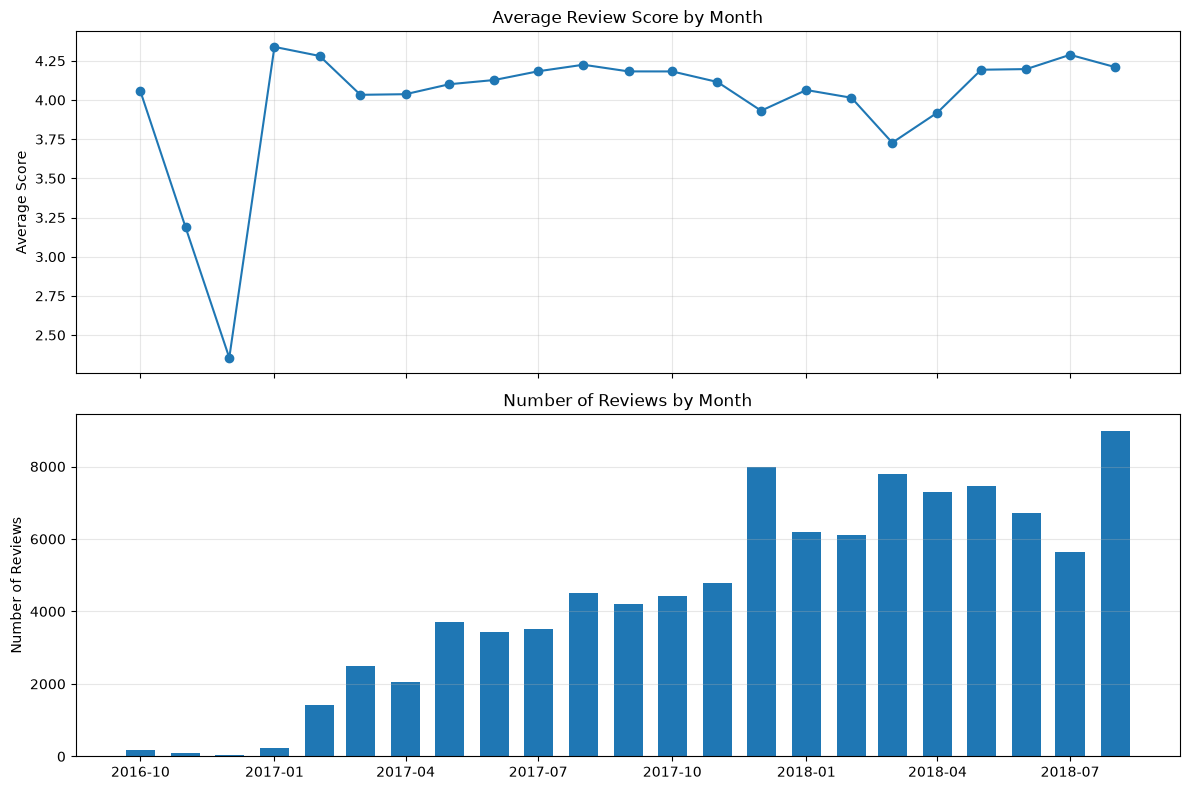

In [20]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(monthly_scores['month'], monthly_scores['average_score'], marker='o')
ax1.set_title('Average Review Score by Month')
ax1.set_ylabel('Average Score')
ax1.grid(alpha=0.3)

ax2.bar(monthly_scores['month'], monthly_scores['review_count'], width=20)
ax2.set_title('Number of Reviews by Month')
ax2.set_ylabel('Number of Reviews')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Months with fewer than 1,000 reviews are the first months of the dataset, and their averages jump around a lot, so they are not reliable:

In [21]:
display(monthly_scores[monthly_scores['review_count'] < 1000].round({'average_score': 2, 'late_percent': 2}))

,month,review_count,average_score,late_percent
0,2016-10-01,179,4.06,0.56
1,2016-11-01,101,3.19,1.98
2,2016-12-01,45,2.36,0.00
3,2017-01-01,239,4.34,0.00


The lowest months with enough reviews, and their share of late orders:

In [22]:
enough_reviews = monthly_scores[monthly_scores['review_count'] >= 1000]
display(enough_reviews.sort_values('average_score').head(5).round({'average_score': 2, 'late_percent': 2}))

,month,review_count,average_score,late_percent
17,2018-03-01,7803,3.73,17.53
18,2018-04-01,7287,3.92,12.74
14,2017-12-01,7982,3.93,11.19
16,2018-02-01,6101,4.01,6.31
5,2017-03-01,2481,4.03,2.70


#### Satisfaction Over Time: Conclusion

**Unreliable months:** the first four months (Oct 2016 to Jan 2017) have fewer than 1,000 reviews each, and Dec 2016 has only 45. Their averages jump from 2.36 to 4.34, which is noise from small samples, not a real trend. They also belong to the incomplete start of the dataset.

All of these months have between 6,000 and 9,000 reviews, so the drops are not caused by small samples. The months with more late orders also have lower scores.

## High-Sales / Low-Satisfaction Categories

We measure sales as the **number of orders** that contain each category:

In [23]:
category_sales = con.sql("""
    SELECT
        p.product_category_name,
        COUNT(DISTINCT oi.order_id) AS orders_count,
        SUM(oi.price) AS revenue
    FROM order_items oi
    JOIN products p
        ON oi.product_id = p.product_id
    GROUP BY p.product_category_name
""").df()

sales_scores = category_sales.merge(category_scores, on='product_category_name')
display(sales_scores.sort_values('orders_count', ascending=False).head(10))

,product_category_name,orders_count,revenue,average_score,review_count
0,bed_bath_table,9417,1036988.68,3.968617,9432
5,health_beauty,8836,1258681.34,4.182189,8826
63,sports_leisure,7720,988048.97,4.168242,7721
14,computers_accessories,6689,911954.32,4.025813,6702
4,furniture_decor,6449,729762.49,4.006040,6457
48,housewares,5884,632248.66,4.142370,5865
68,watches_gifts,5624,1205005.68,4.065700,5586
49,telephony,4199,323667.53,4.004074,4173
43,auto,3897,592720.11,4.090629,3895
16,toys,3886,483946.60,4.188293,3861


**High sales** = at least 1,000 orders. **Low satisfaction** = average score below the average of all category reviews:

In [24]:
high_sales_low_score = sales_scores[(sales_scores['orders_count'] >= 1000) & (sales_scores['average_score'] < category_average)]

print(f"average score of all category reviews: {category_average.round(2)}")
display(high_sales_low_score.sort_values('orders_count', ascending=False))

average score of all category reviews: 4.1


,product_category_name,orders_count,revenue,average_score,review_count
0,bed_bath_table,9417,1036988.68,3.968617,9432
14,computers_accessories,6689,911954.32,4.025813,6702
4,furniture_decor,6449,729762.49,4.006040,6457
68,watches_gifts,5624,1205005.68,4.065700,5586
49,telephony,4199,323667.53,4.004074,4173
43,auto,3897,592720.11,4.090629,3895
27,baby,2885,411764.89,4.039735,2869
7,electronics,2550,160246.74,4.095577,2532
44,unknown,1451,179535.28,3.913674,1448
6,office_furniture,1273,273960.70,3.617508,1268


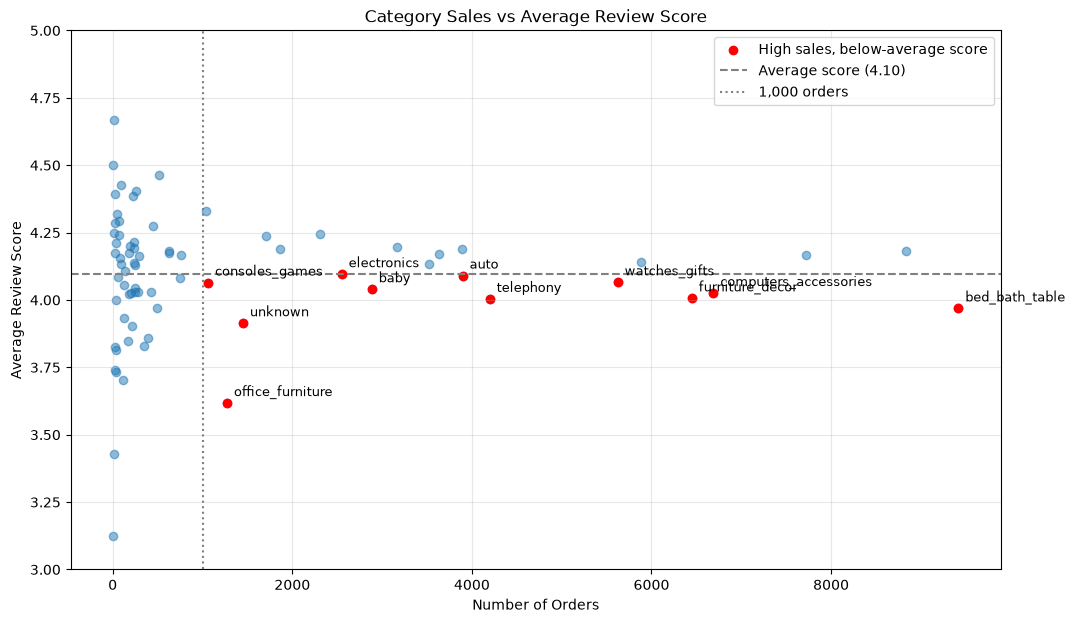

In [25]:
plt.figure(figsize=(12, 7))

plt.scatter(sales_scores['orders_count'], sales_scores['average_score'], alpha=0.5)
plt.scatter(high_sales_low_score['orders_count'], high_sales_low_score['average_score'], color='red',
            label='High sales, below-average score')

# write the names of the red categories next to their points
for i, row in high_sales_low_score.iterrows():
    plt.annotate(row['product_category_name'], (row['orders_count'], row['average_score']),
                 xytext=(5, 5), textcoords='offset points', fontsize=9)

plt.axhline(category_average, color='gray', linestyle='--', label=f'Average score ({category_average:.2f})')
plt.axvline(1000, color='gray', linestyle=':', label='1,000 orders')

plt.ylim(3, 5)
plt.title('Category Sales vs Average Review Score')
plt.xlabel('Number of Orders')
plt.ylabel('Average Review Score')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### High-Sales / Low-Satisfaction Categories: Conclusion

11 categories have **at least 1,000 orders** and an average score **below 4.10**:

| Category | Orders | Average score |
|---|---|---|
| bed_bath_table | 9,417 | 3.97 |
| computers_accessories | 6,689 | 4.03 |
| furniture_decor | 6,449 | 4.01 |
| watches_gifts | 5,624 | 4.07 |
| telephony | 4,199 | 4.00 |
| auto | 3,897 | 4.09 |
| baby | 2,885 | 4.04 |
| electronics | 2,550 | 4.10 |
| unknown | 1,451 | 3.91 |
| office_furniture | 1,273 | 3.62 |
| consoles_games | 1,062 | 4.06 |

Not all of them need the same attention. `auto` and `electronics` are only 0.01 below the average, so they are basically average.

**Categories to investigate first:**
1. **office_furniture**: far below every other large category (3.62).
2. **bed_bath_table**: the category with the most orders, and below average (3.97). Even a small improvement here affects many customers.
3. **furniture_decor, telephony, computers_accessories**: large categories (4,000+ orders) about 0.1 below average.
4. **unknown**: products with no category information score low (3.91). This is also a data quality issue.

On the other hand, `health_beauty` and `sports_leisure` are among the biggest categories and score above average, so high sales don't always mean low satisfaction.

## Delivery Performance vs Customer Satisfaction

We only use delivered orders that have a delivery date. `is_late` is True when the order arrived after the estimated date:

In [26]:
delivery_scores = con.sql("""
    SELECT
        CASE WHEN o.is_late THEN 'Late' ELSE 'On time' END AS delivery,
        COUNT(DISTINCT o.order_id) AS orders_count,
        COUNT(*) AS review_count,
        AVG(r.review_score) AS average_score
    FROM reviews r
    JOIN orders o
        ON r.order_id = o.order_id
    WHERE o.order_status = 'delivered'
        AND o.is_late IS NOT NULL
    GROUP BY delivery
    ORDER BY delivery DESC
""").df()

delivery_scores['review_percent'] = delivery_scores['review_count'] / delivery_scores['review_count'].sum() * 100
display(delivery_scores.round(2))

,delivery,orders_count,review_count,average_score,review_percent
0,On time,89443,89944,4.29,93.35
1,Late,6381,6409,2.27,6.65


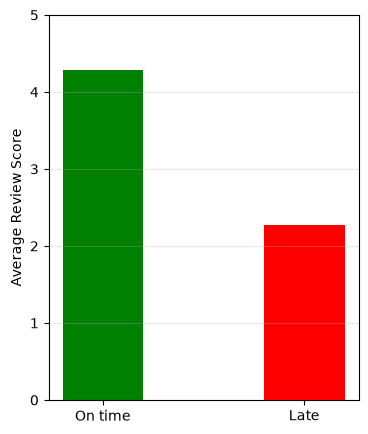

In [27]:
plt.figure(figsize=(4, 5))
plt.bar(delivery_scores['delivery'], delivery_scores['average_score'], color=['green', 'red'], width=0.4)
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.grid(axis='y', alpha=0.3)
plt.show()

Now we divide the late orders by how many days late they were:

In [28]:
delay_scores = con.sql("""
    SELECT
        CASE
            WHEN o.delivery_delay_days <= 3 THEN '1-3 days'
            WHEN o.delivery_delay_days <= 7 THEN '4-7 days'
            ELSE 'more than 7 days'
        END AS delay_range,
        COUNT(DISTINCT o.order_id) AS orders_count,
        COUNT(*) AS review_count,
        AVG(r.review_score) AS average_score
    FROM reviews r
    JOIN orders o
        ON r.order_id = o.order_id
    WHERE o.order_status = 'delivered'
        AND o.is_late = TRUE
    GROUP BY delay_range
    ORDER BY delay_range
""").df()

display(delay_scores.round(2))

,delay_range,orders_count,review_count,average_score
0,1-3 days,1852,1856,3.29
1,4-7 days,1748,1756,2.10
2,more than 7 days,2781,2797,1.70


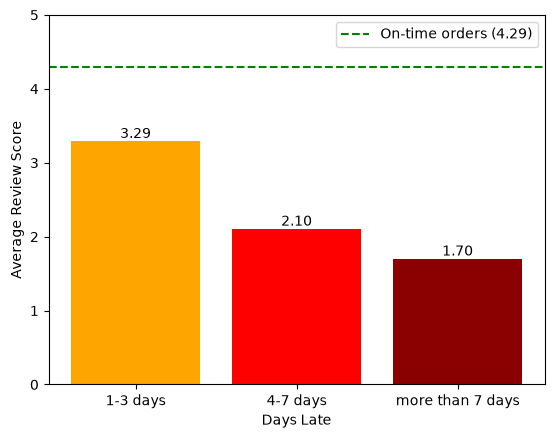

In [29]:
bars = plt.bar(delay_scores['delay_range'], delay_scores['average_score'], color=['orange', 'red', 'darkred'])
plt.bar_label(bars, fmt='%.2f')

on_time_score = delivery_scores.loc[delivery_scores['delivery'] == 'On time', 'average_score'].values[0]
plt.axhline(on_time_score, color='green', linestyle='--', label=f'On-time orders ({on_time_score:.2f})')
plt.xlabel('Days Late')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.legend()
plt.show()

#### Delivery Performance vs Satisfaction: Conclusion


- Late orders are only **6.65%** of the reviews, but their average score is **2.02 points lower** than on-time orders.
- Even a short delay (1 to 3 days) is associated with a score about **1 point lower** than on-time orders. After a week, the average is close to 1 star.
- Every group has more than 1,700 reviews, so these results are not caused by small samples.

**Late deliveries are associated with lower average review scores, and longer delays with even lower scores.**

## Category-Level Delivery and Satisfaction

We join our review-category table (`reviews_products`, one row per review and category) with the orders, and compare on-time and late orders inside each category:

In [30]:
category_delivery = con.sql("""
    SELECT
        rp.product_category_name,
        CASE WHEN o.is_late THEN 'late' ELSE 'on_time' END AS delivery,
        COUNT(*) AS review_count,
        AVG(rp.review_score) AS average_score
    FROM reviews_products rp
    JOIN orders o
        ON rp.order_id = o.order_id
    WHERE o.order_status = 'delivered'
        AND o.is_late IS NOT NULL
    GROUP BY rp.product_category_name, delivery
""").df()

# one row per category: on-time and late side by side
category_compare = category_delivery.pivot(index='product_category_name', columns='delivery',
                                           values=['average_score', 'review_count'])
category_compare.columns = ['late_score', 'on_time_score', 'late_reviews', 'on_time_reviews']
category_compare['difference'] = category_compare['on_time_score'] - category_compare['late_score']

display(category_compare.head())

,late_score,on_time_score,late_reviews,on_time_reviews,difference
product_category_name,,,,,
agro_industry_and_commerce,1.714286,4.205882,7.0,170.0,2.491597
air_conditioning,2.111111,4.193133,9.0,233.0,2.082022
art,2.500000,4.204420,12.0,181.0,1.704420
arts_and_craftmanship,1.000000,4.318182,1.0,22.0,3.318182
audio,1.725000,4.107843,40.0,306.0,2.382843


Late orders are only about 7% of all orders, so we keep categories with **at least 50 late reviews** (and therefore many more on-time reviews):

In [31]:
enough_late = category_compare[category_compare['late_reviews'] >= 50].sort_values('difference')

print(f"categories with at least 50 late reviews: {len(enough_late)}")
display(enough_late.round(2))

categories with at least 50 late reviews: 22


,late_score,on_time_score,late_reviews,on_time_reviews,difference
product_category_name,,,,,
office_furniture,2.35,3.76,100.0,1149.0,1.41
telephony,2.43,4.18,287.0,3786.0,1.74
furniture_decor,2.33,4.18,441.0,5876.0,1.85
electronics,2.39,4.27,190.0,2309.0,1.88
bed_bath_table,2.23,4.14,679.0,8616.0,1.91
computers_accessories,2.28,4.20,409.0,6139.0,1.92
auto,2.31,4.29,274.0,3533.0,1.98
garden_tools,2.32,4.31,222.0,3216.0,1.99
health_beauty,2.35,4.38,637.0,8017.0,2.03


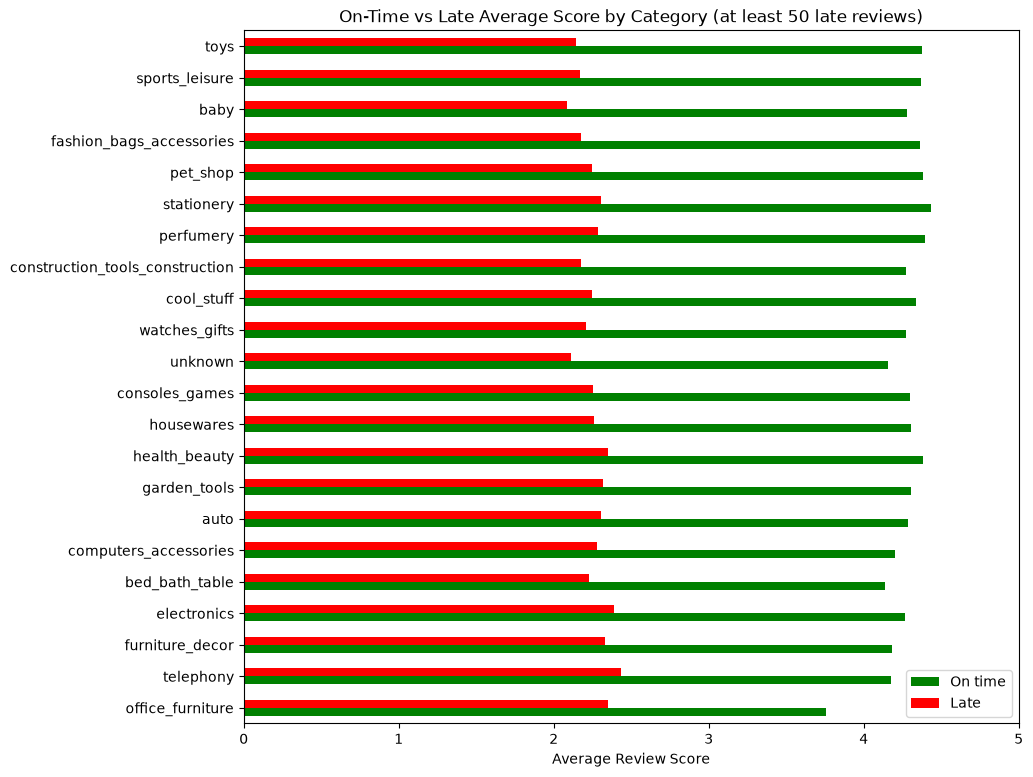

In [32]:
chart = enough_late[['on_time_score', 'late_score']]
chart.plot(kind='barh', figsize=(10, 9), color=['green', 'red'])

plt.title('On-Time vs Late Average Score by Category (at least 50 late reviews)')
plt.xlabel('Average Review Score')
plt.ylabel('')
plt.xlim(0, 5)
plt.legend(['On time', 'Late'])
plt.show()

In [33]:
print(f"smallest drop: {enough_late['difference'].min():.2f} points ({enough_late['difference'].idxmin()})")
print(f"largest drop : {enough_late['difference'].max():.2f} points ({enough_late['difference'].idxmax()})")
print(f"categories where late orders score lower: {(enough_late['difference'] > 0).sum()} of {len(enough_late)}")

smallest drop: 1.41 points (office_furniture)
largest drop : 2.23 points (toys)
categories where late orders score lower: 22 of 22


#### Category-Level Delivery and Satisfaction: Conclusion

We compared the 22 categories with at least 50 late reviews:

- **In all 22 categories, late orders score lower** than on-time orders. The drop goes from **1.41** points (`office_furniture`) to **2.23** points (`toys`).
- **Late orders score about the same in every category (2.1 to 2.4)**, while on-time scores differ more (3.76 to 4.43). In other words, when an order is late, customers are unhappy no matter what they bought.
- The **biggest drops** are in `toys` (2.23), `sports_leisure` (2.20), `baby` and `fashion_bags_accessories` (2.19 each). These categories score well when on time, so a delay costs them the most.
- **office_furniture** has the smallest drop because its on-time score is already low (3.76). Its problem is not only delivery: even on-time office furniture orders score below the other categories.

So the relationship between delays and lower scores is very consistent across categories. Only the size of the drop changes. The late groups are small in some categories (50 to 100 reviews), so their exact averages are less precise.

Limits:
- **Reviews are for whole orders:** a category score is the score of orders that contain the category, not a rating of the product. 786 orders contain more than one category, and their review counts in each of them. 547 orders have more than one review.
- **Small samples:** categories with few reviews (and months with few reviews) have unreliable averages. The thresholds used here (100 reviews per category, 1,000 per month, 50 late reviews, 1,000 orders for "high sales") are reasonable choices, but different thresholds would change the lists slightly.
- **Monthly scores use the review date,** not the purchase date, so a review can fall in the month after the order.

## Final Conclusion

1. **Overall, customers are satisfied:** the average score is 4.09 and 77% of reviews are positive. But about **1 in 7 reviews is negative**, and 1 star is more common than 2 or 3 stars, so there is a clear group of very unhappy customers.
2. **Category matters, but less than delivery:** among categories with enough reviews, averages range from 3.62 (`office_furniture`) to 4.46 (`books_general_interest`). Small categories (fewer than 30 reviews) should not be ranked.
3. **Some large categories need attention:** `office_furniture`, `bed_bath_table`, `furniture_decor`, `telephony`, `computers_accessories` and `unknown` combine high sales with below-average satisfaction.
4. **Satisfaction dropped when deliveries were late:** the biggest monthly drops (Dec 2017, Mar and Apr 2018) happened in the months with the most late orders, and satisfaction recovered when late orders fell.
5. **Delivery delays are the strongest pattern in this analysis:** late orders average 2.27 vs 4.29 for on-time orders, scores fall further as the delay grows (3.29, then 2.10, then 1.70), and this happens in every category we checked.

**Recommendation:** improving on-time delivery (especially avoiding delays of more than 3 days) is the most promising way to reduce negative reviews. `office_furniture` should be investigated separately, because its scores are low even when delivery is on time. These results show associations; a deeper analysis that also looks at sellers, price and region would be needed to confirm the causes.

In [34]:
con.close()